## Part 3: Feature Analysis and Linear Regression

In this section, we explore possible improvements to the
Ames Housing dataset based on the exploratory analysis.

We focus on:
- External data enrichment
- Candidates for feature removal
- Feature engineering
- Linear regression (bonus)

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

housing = pd.read_csv(
    "data/AmesHousing.csv",
    sep="\t",
    keep_default_na=False,
    na_values=[""]
)

print("Dataset shape:", housing.shape)
display(housing.head())

Dataset shape: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NA,IR1,Lvl,...,0,NA,NA,NA,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NA,Reg,Lvl,...,0,NA,MnPrv,NA,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NA,IR1,Lvl,...,0,NA,NA,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NA,Reg,Lvl,...,0,NA,NA,NA,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NA,IR1,Lvl,...,0,NA,MnPrv,NA,0,3,2010,WD,Normal,189900


## 3.1 External Data Enrichment

**Question:** What external information could improve
the Ames Housing dataset?

The exploratory analysis showed that house prices vary
considerably between neighborhoods. Although the dataset
already contains `Neighborhood`, `Condition 1`, and
`Condition 2`, additional information could help explain
some of these differences.

### 1. Location and Accessibility

We could add distances to schools, shops, public transport,
and other important facilities.

Two houses in the same neighborhood may have different
levels of accessibility, which could influence their value.

However, precise property locations would be needed to
calculate these distances reliably.

### 2. Historical Economic Conditions

The dataset contains sales from 2006 to 2010. Historical
mortgage interest rates or local housing market indicators
could provide useful economic context.

These values could be linked using `Yr Sold` and `Mo Sold`.

They might help explain price differences that are not
directly related to the physical characteristics of a house.

### 3. Additional Parcel Information

According to the dataset documentation, `PID` (Parcel Identification Number) identifies
the parcel and may be useful for looking up additional
property records.

This could help us obtain more detailed geographical or
land-related information, if suitable historical records
are available.

### 4. Environmental Risk

Flood risk or environmental noise information could provide
additional context about the attractiveness of a location.

Such information would need to be matched to the property
location and ideally represent conditions around the time
of sale.

### Conclusion

External data could provide additional information about
location, economic conditions, and environmental factors.

These features might improve future price prediction models,
but their usefulness would need to be tested experimentally.

## 3.2 Candidates for Feature Removal

In [58]:
# Check missing values and correlations for removal candidates

print("Missing values in Lot Frontage:")
print(housing["Lot Frontage"].isna().sum()) # identifical valorile lipsa, le numara

print("\nCorrelation between Garage Cars and Garage Area:")
print(housing["Garage Cars"].corr(housing["Garage Area"])) # correlatie

print("\nCorrelation between TotRms AbvGrd and Gr Liv Area:")
print(housing["TotRms AbvGrd"].corr(housing["Gr Liv Area"]))

print("\nUnique values in Order and PID:")
print(housing[["Order", "PID"]].nunique()) # numara cate valori distincet exista intr o coloana

Missing values in Lot Frontage:
490

Correlation between Garage Cars and Garage Area:
0.8896762825411669

Correlation between TotRms AbvGrd and Gr Liv Area:
0.8077721448904692

Unique values in Order and PID:
Order    2930
PID      2930
dtype: int64


### Interpretation — Candidates for Feature Removal

We identified several features that could be reconsidered for future ML models:

**1. Identifiers — `Order` and `PID`**

Both have 2,930 unique values and do not directly describe property characteristics. They are strong candidates for exclusion as numerical predictors, although `PID` could still be useful for linking external data.

**2. Potentially redundant features**

- `Garage Cars` and `Garage Area`: r = 0.890
- `TotRms AbvGrd` and `Gr Liv Area`: r = 0.808

These pairs contain overlapping information. However, strong correlation does not necessarily make a feature redundant. Their usefulness should be tested before removal.

**3. Missing values — `Lot Frontage`**

490 values (16.72%) are missing. Removing this feature could simplify preprocessing, but imputing the missing values might preserve useful information.

**4. Features requiring careful interpretation**

- `Overall Cond` has a weak correlation with `SalePrice` (≈ -0.1), but may still be useful.
- `NA` in `Pool QC` or `Fence` can indicate the absence of a facility, not missing data.
- `MS SubClass` represents categories despite being numerically encoded.

### Conclusion

`Order` and `PID` are the strongest candidates for exclusion as numerical predictors. Other features require further evaluation, so no columns are removed at this stage.

## 3.3 Feature Engineering

We investigate whether combining existing features could
provide more meaningful information for future prediction models.

The original dataset will remain unchanged.

In [59]:
# Create a copy to keep the original dataset unchanged
features = housing.copy()

# Age of the house at the time of sale
features["HouseAge"] = features["Yr Sold"] - features["Year Built"]

# Time since the last recorded remodeling/addition
features["YearsSinceRemodel"] = (
    features["Yr Sold"] - features["Year Remod/Add"]
)

# Whether remodeling or an addition was recorded
features["WasRemodeled"] = (
    features["Year Remod/Add"] > features["Year Built"]
).astype(int)

# Above-ground living area plus basement area
features["TotalArea"] = (
    features["Gr Liv Area"] + features["Total Bsmt SF"]
)

# Full bathrooms count as 1, half bathrooms as 0.5
features["TotalBathrooms"] = (
    features["Full Bath"]
    + features["Bsmt Full Bath"]
    + 0.5 * (features["Half Bath"] + features["Bsmt Half Bath"])
)

new_features = [
    "HouseAge",
    "YearsSinceRemodel",
    "WasRemodeled",
    "TotalArea",
    "TotalBathrooms"
]

display(features[new_features].describe().round(2))

,HouseAge,YearsSinceRemodel,WasRemodeled,TotalArea,TotalBathrooms
count,2930.00,2930.00,2930.00,2929.00,2928.00
mean,36.43,23.52,0.46,2551.51,2.22
std,30.29,20.86,0.50,804.81,0.81
min,-1.00,-2.00,0.00,334.00,1.00
25%,7.00,4.00,0.00,2004.00,1.50
50%,34.00,15.00,0.00,2452.00,2.00
75%,54.00,42.75,1.00,2995.00,2.50
max,136.00,60.00,1.00,11752.00,7.00


In [60]:
print("Houses with a recorded remodel/addition:")
print(features["WasRemodeled"].value_counts())

print("\nNegative house ages:")
print((features["HouseAge"] < 0).sum()) # o fost vanduta in 2008 si construita in 2009 - o fi o zona buna

print("\nNegative years since remodeling:") 
print((features["YearsSinceRemodel"] < 0).sum()) # possible data leakage. daca o vand in 2008 nu am voie sa stiu daca a fost renovata in 2010

Houses with a recorded remodel/addition:
WasRemodeled
0    1570
1    1360
Name: count, dtype: int64

Negative house ages:
1

Negative years since remodeling:
3


In [61]:
# Inspect properties with negative ages
suspicious = features[
    (features["HouseAge"] < 0) |
    (features["YearsSinceRemodel"] < 0)
]

display(suspicious[[
    "Order",
    "Yr Sold",
    "Year Built",
    "Year Remod/Add",
    "HouseAge",
    "YearsSinceRemodel",
    "SalePrice"
]])

,Order,Yr Sold,Year Built,Year Remod/Add,HouseAge,YearsSinceRemodel,SalePrice
1702,1703,2007,2007,2008,0,-1,260116
2180,2181,2007,2008,2009,-1,-2,183850
2181,2182,2007,2007,2008,0,-1,184750


In [62]:
# Check missing values in the new features
print(features[new_features].isna().sum()) 

HouseAge             0
YearsSinceRemodel    0
WasRemodeled         0
TotalArea            1
TotalBathrooms       2
dtype: int64


### Interpretation — Feature Engineering

We created five new features to better represent property age, renovation history, size, and facilities.

**1. Age and Remodeling**
- Median `HouseAge`: **34 years**; median `YearsSinceRemodel`: **15 years**.
- **1,360 properties (46.4%)** have a recorded remodeling/addition after construction.

These features may help distinguish older renovated houses from those without recorded improvements.

**2. Area and Bathrooms**
- Median `TotalArea`: **2,452 sqft** (living area + basement).
- Median `TotalBathrooms`: **2** (full baths + 0.5 × half baths).

These features summarize property size and facilities, although basement space is not necessarily fully finished.

**3. Data Quality**
- **1** negative `HouseAge` and **3** negative `YearsSinceRemodel` values.
- **1** missing `TotalArea` and **2** missing `TotalBathrooms` values.

Negative ages require investigation, as using information recorded after the sale could introduce **data leakage**.

**Conclusion:** The proposed features may be useful for future ML models, but their predictive value remains untested. Missing or inconsistent values should be addressed before modeling.

## 3.4 Bonus — Linear Regression

We investigate two pairs of features that may have
approximately linear relationships.

For each pair, we visualize the relationship, fit a
linear regression model, compare actual and predicted
values, and discuss whether the observed correlation
is meaningful or potentially misleading.

### 3.4.1 Living Area vs Sale Price

**Question:** How well can living area predict house prices?

We investigate the relationship using linear regression
and compare actual prices with model predictions.

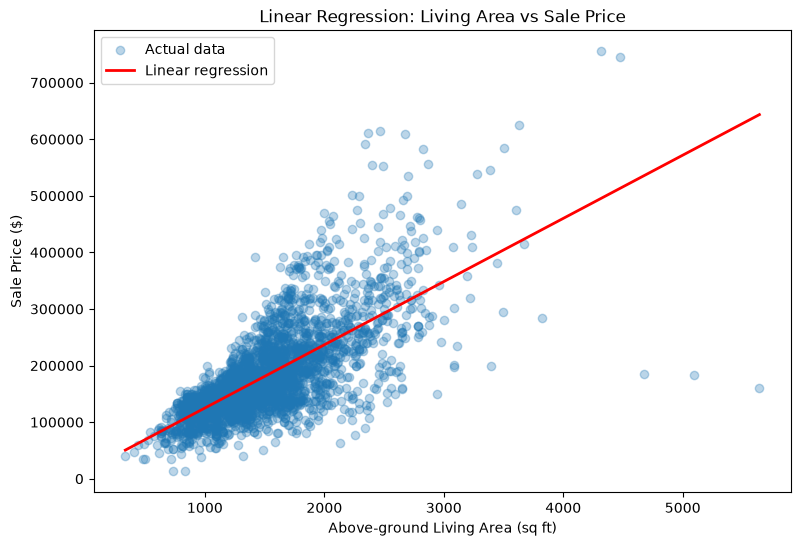

Slope: 111.6940008578003
Intercept: 13289.634364759637
R²: 0.49953785669572837


In [ ]:
from sklearn.linear_model import LinearRegression

regression_data = housing[["Gr Liv Area", "SalePrice"]].dropna() # elimina doar din acest subset eventualele randuri cu val lispa

# Input feature and target
X = regression_data[["Gr Liv Area"]] # ce primeste randuri x features - bidrectionalș
y = regression_data["SalePrice"] # rasounsuril

# Train the linear regression model
model1 = LinearRegression()
model1.fit(X, y)

# Generate points for the regression line
x_line = np.linspace(X.min().iloc[0], X.max().iloc[0], 100)
line_data = pd.DataFrame({"Gr Liv Area": x_line})
y_line = model1.predict(line_data)

# Plot data points and regression line
plt.figure(figsize=(9, 6))

plt.scatter(X["Gr Liv Area"], y, alpha=0.3, label="Actual data")
plt.plot(x_line, y_line, color="red", linewidth=2,
         label="Linear regression")

plt.xlabel("Above-ground Living Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.title("Linear Regression: Living Area vs Sale Price")
plt.legend()
plt.show()

# Display model results
print("Slope:", model1.coef_[0]) # Înseamnă că pentru fiecare sqft suplimentar, modelul estimează o creștere a prețului de aproximativ 112 dolari.
print("Intercept:", model1.intercept_) # Este valoarea la care dreapta intersectează axa Y, adică prețul estimat matematic pentru o suprafață de zero.
print("R²:", model1.score(X, y)) #Acesta măsoară cât de bine se potrivește modelul cu datele. În cazul nostru, regresia explică aproximativ 50% din variația prețurilor în datele de antrenare.

#Aici intervine metoda Ordinary Least Squares (OLS), folosită implicit de LinearRegression.
#Pentru fiecare punct:
# - Avem valoarea reală \(y\).
# - Modelul calculează o valoare estimată \(\hat y\).
# - Diferența \(y-\hat y\) se numește eroare sau reziduu (residual).
# Modelul caută dreapta care minimizează suma pătratelor acestor erori.
# De ce pătrate? Pentru ca erorile pozitive și negative să nu se anuleze și pentru ca erorile mari să fie penalizate mai mult.

In [64]:
# Compare actual and predicted prices for 5 existing houses
sample = regression_data.head(5).copy()

sample["PredictedPrice"] = model1.predict(sample[["Gr Liv Area"]])
sample["Error"] = sample["SalePrice"] - sample["PredictedPrice"]

display(sample.round(2))

,Gr Liv Area,SalePrice,PredictedPrice,Error
0,1656,215000,198254.90,16745.10
1,896,105000,113367.46,-8367.46
2,1329,172000,161730.96,10269.04
3,2110,244000,248963.98,-4963.98
4,1629,189900,195239.16,-5339.16


In [65]:
# Predict prices for new hypothetical houses
new_houses = pd.DataFrame({
    "Gr Liv Area": [1000, 1500, 2000]
})

new_houses["PredictedPrice"] = model1.predict(new_houses)

display(new_houses.round(2))

,Gr Liv Area,PredictedPrice
0,1000,124983.64
1,1500,180830.64
2,2000,236677.64


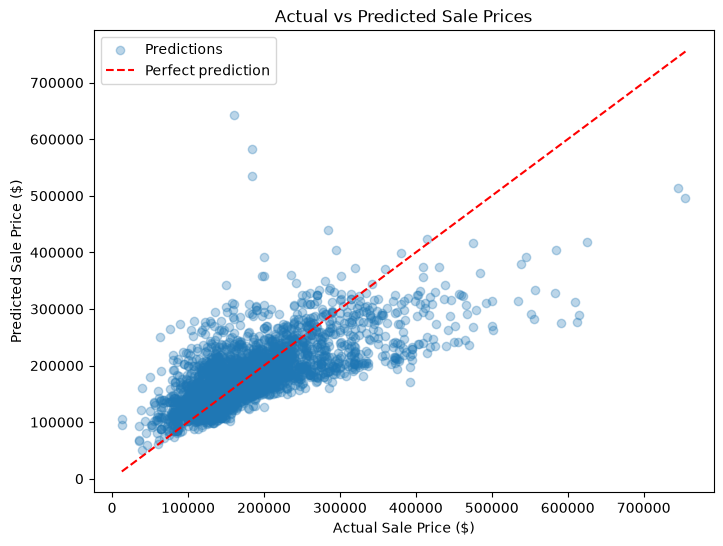

In [66]:
# Predict prices for all houses in the dataset
predicted_prices = model1.predict(X)

plt.figure(figsize=(8, 6))

plt.scatter(y, predicted_prices, alpha=0.3, label="Predictions")

# Reference line for perfect predictions
min_price = min(y.min(), predicted_prices.min())
max_price = max(y.max(), predicted_prices.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.title("Actual vs Predicted Sale Prices")
plt.legend()
plt.show()

**Interpretation**

- **R² = 0.50:** The linear model explains approximately 50% of the variation in sale prices in the training data.
- **Slope = 111.69:** Each additional square foot is associated with an estimated $112 increase in price.
- Larger houses show greater price variability, and several outliers are visible.
- For five existing houses, absolute prediction errors range from $4,964 to $16,745.
- For hypothetical houses of 1,000, 1,500, and 2,000 sqft, predicted prices are approximately $124,984, $180,831, and $236,678.

The model tends to underestimate expensive properties. Factors such as quality and neighborhood may also influence prices, so the correlation does not necessarily imply causation.

### 3.4.2 Garage Area vs Garage Cars

**Question:** Can garage capacity be estimated from garage area?

We investigate this relationship using linear regression
and examine whether properties without garages affect the correlation.

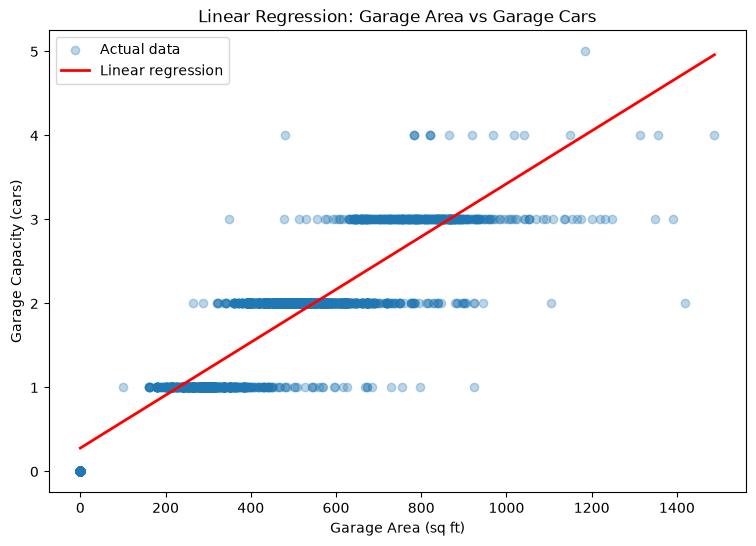

Slope: 0.003146564596229928
Intercept: 0.27905677804429185
R²: 0.7915238877162717


In [67]:
# Select data for the second regression
garage_data = housing[["Garage Area", "Garage Cars"]].dropna()

X2 = garage_data[["Garage Area"]]
y2 = garage_data["Garage Cars"]

# Train the model
model2 = LinearRegression()
model2.fit(X2, y2)

# Generate the regression line
x_line2 = np.linspace(X2.min().iloc[0], X2.max().iloc[0], 100)
line_data2 = pd.DataFrame({"Garage Area": x_line2})
y_line2 = model2.predict(line_data2)

# Visualize
plt.figure(figsize=(9, 6))

plt.scatter(X2["Garage Area"], y2, alpha=0.3, label="Actual data")
plt.plot(x_line2, y_line2, color="red",
         linewidth=2, label="Linear regression")

plt.xlabel("Garage Area (sq ft)")
plt.ylabel("Garage Capacity (cars)")
plt.title("Linear Regression: Garage Area vs Garage Cars")
plt.legend()
plt.show()

print("Slope:", model2.coef_[0])
print("Intercept:", model2.intercept_)
print("R²:", model2.score(X2, y2))

In [68]:
# Check whether houses without garages affect the correlation
all_corr = garage_data["Garage Area"].corr(garage_data["Garage Cars"])

garage_only = garage_data[garage_data["Garage Area"] > 0]

garage_corr = garage_only["Garage Area"].corr(garage_only["Garage Cars"])

print("Correlation (all houses):", round(all_corr, 3))
print("Correlation (houses with garages):", round(garage_corr, 3))
print("Houses without garage:", len(garage_data) - len(garage_only))

Correlation (all houses): 0.89
Correlation (houses with garages): 0.845
Houses without garage: 157


In [69]:
# Compare actual and predicted garage capacities
garage_sample = garage_data.head(5).copy()

garage_sample["PredictedCars"] = model2.predict(
    garage_sample[["Garage Area"]]
)

garage_sample["Error"] = (
    garage_sample["Garage Cars"] - garage_sample["PredictedCars"]
)

display(garage_sample.round(2))

,Garage Area,Garage Cars,PredictedCars,Error
0,528.0,2.0,1.94,0.06
1,730.0,1.0,2.58,-1.58
2,312.0,1.0,1.26,-0.26
3,522.0,2.0,1.92,0.08
4,482.0,2.0,1.80,0.20


In [70]:
# Predict capacity for new hypothetical garages
new_garages = pd.DataFrame({
    "Garage Area": [250, 500, 750]
})

new_garages["PredictedCars"] = model2.predict(new_garages)

display(new_garages.round(2))

,Garage Area,PredictedCars
0,250,1.07
1,500,1.85
2,750,2.64


**Interpretation**

- **R² = 0.79:** Garage area explains approximately 79% of the variation in garage capacity.
- **Slope = 0.00315:** An additional 100 sqft corresponds to approximately 0.315 more cars in predicted capacity.
- Excluding 157 properties without garages reduces the correlation from **0.890 to 0.845**, but the relationship remains strong.
- A 730 sqft garage accommodates only 1 car, although the model predicts 2.58.
- For hypothetical garages of 250, 500, and 750 sqft, predictions are 1.07, 1.85, and 2.64 cars.

The relationship is meaningful but not perfect. Garage layout may influence capacity, and linear regression can predict fractional values for a discrete feature.

### 3.4.3 Comparison and Conclusions

Both models show positive linear relationships.

The garage model achieves a higher R² (0.79) than the sale price model (0.50), indicating a stronger fit to its respective target.

However, high correlation does not guarantee accurate individual predictions or establish causation.

Both models were trained and evaluated on the same data. A train-test split would be needed to assess their performance on unseen observations.